In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("Book1.xlsx")

In [3]:
df.head()

,Statistic Label,Month,Type of Residential Property,UNIT,VALUE
0,Residential Property Price Index,2005 January,National - all residential properties,Base 2015=100,124.9
1,Residential Property Price Index,2005 January,National - houses,Base 2015=100,120.7
2,Residential Property Price Index,2005 January,National - apartments,Base 2015=100,153.4
3,Residential Property Price Index,2005 January,Dublin - all residential properties,Base 2015=100,118.5
4,Residential Property Price Index,2005 January,Dublin - houses,Base 2015=100,112.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 5 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Statistic Label               20800 non-null  str    
 1   Month                         20800 non-null  str    
 2   Type of Residential Property  20800 non-null  str    
 3   UNIT                          20800 non-null  str    
 4   VALUE                         17840 non-null  float64
dtypes: float64(1), str(4)
memory usage: 812.6 KB


In [5]:
df.isna().sum()

Statistic Label                    0
Month                              0
Type of Residential Property       0
UNIT                               0
VALUE                           2960
dtype: int64

In [6]:
rppi = df[
(df["Statistic Label"] == "Residential Property Price Index") &
(df["Type of Residential Property"] == "National - all residential properties")
]

In [7]:
rppi.head()

,Statistic Label,Month,Type of Residential Property,UNIT,VALUE
0,Residential Property Price Index,2005 January,National - all residential properties,Base 2015=100,124.9
20,Residential Property Price Index,2005 February,National - all residential properties,Base 2015=100,125.9
40,Residential Property Price Index,2005 March,National - all residential properties,Base 2015=100,126.6
60,Residential Property Price Index,2005 April,National - all residential properties,Base 2015=100,127.5
80,Residential Property Price Index,2005 May,National - all residential properties,Base 2015=100,128.4


In [8]:
rppi.shape

(260, 5)

In [9]:
rppi["VALUE"].isna().sum()

np.int64(0)

In [10]:
prophet_df = rppi[["Month", "VALUE"]].copy()

In [11]:
prophet_df.columns = ["ds", "y"]

In [12]:
prophet_df["ds"] = pd.to_datetime(prophet_df["ds"])

C:\Users\IrynaZ(DA-IRE6)\AppData\Local\Temp\ipykernel_4748\1441936613.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  prophet_df["ds"] = pd.to_datetime(prophet_df["ds"])


In [13]:
prophet_df = prophet_df.reset_index(drop=True)

prophet_df.head()

,ds,y
0,2005-01-01,124.9
1,2005-02-01,125.9
2,2005-03-01,126.6
3,2005-04-01,127.5
4,2005-05-01,128.4


In [14]:
prophet_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      260 non-null    datetime64[us]
 1   y       260 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 4.2 KB


In [15]:
from prophet import Prophet

Importing plotly failed. Interactive plots will not work.


In [16]:
model = Prophet()
model.fit(prophet_df)


C:\Users\IrynaZ(DA-IRE6)\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
20:13:11 - cmdstanpy - INFO - Chain [1] start processing
20:13:12 - cmdstanpy - INFO - Chain [1] done processing


In [17]:
future = model.make_future_dataframe(
    periods=12,
    freq='MS'
)

future.tail()

,ds
267,2027-04-01
268,2027-05-01
269,2027-06-01
270,2027-07-01
271,2027-08-01


In [18]:
forecast = model.predict(future)

yhat = predicted RPPI
yhat_lower = pessimistic estimate
yhat_upper = optimistic estimate

In [19]:
forecast[['ds','yhat','yhat_lower','yhat_upper']].tail(12)

,ds,yhat,yhat_lower,yhat_upper
260,2026-09-01,211.746524,209.142153,214.234412
261,2026-10-01,212.813879,210.347819,215.304683
262,2026-11-01,213.707309,211.175033,216.269424
263,2026-12-01,214.410384,211.842607,217.048276
264,2027-01-01,215.057224,212.381339,217.747030
265,2027-02-01,215.218468,212.459535,218.013192
266,2027-03-01,215.831963,212.847224,218.696725
267,2027-04-01,216.731654,213.364043,219.835131
268,2027-05-01,217.645443,214.212688,221.168890
269,2027-06-01,219.171172,215.782667,222.915465


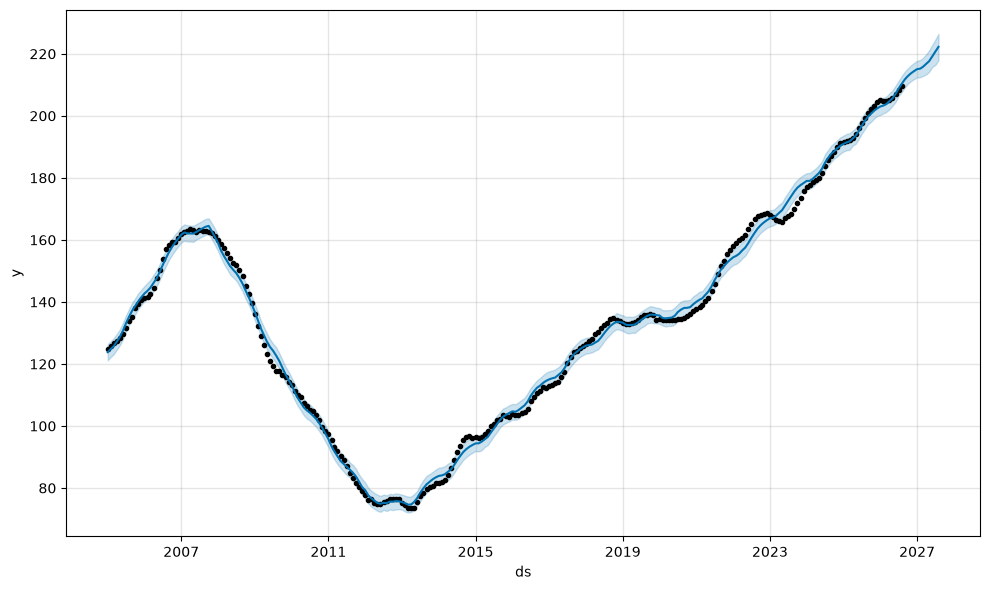

In [20]:
fig = model.plot(forecast)
plt.show()

In [21]:
current = prophet_df['y'].iloc[-1]

predicted = forecast['yhat'].iloc[-1]

growth = ((predicted - current) / current) * 100

print(f"Current RPPI: {current:.1f}")
print(f"Forecast RPPI: {predicted:.1f}")
print(f"Expected growth: {growth:.2f}%")

Current RPPI: 209.7
Forecast RPPI: 222.2
Expected growth: 5.98%


Insight:
Based on Prophet forecasting, Ireland's Residential Property Price Index is expected to increase from 209.7 to 222.2 over the next 12 months, representing an estimated 5.98% increase. This suggests continued growth in residential property prices, although at a relatively moderate pace rather than a rapid market expansion.

Recommendation:
The forecast indicates that residential property prices are likely to continue rising over the next year. Property developers and investors may benefit from advancing acquisition and development plans before further price increases occur. However, the projected growth rate of approximately 6% suggests a stable market environment rather than an overheated market, supporting cautious but positive investment decisions.